# FD001 remaining useful life: tuned Logistic Regression, Random Forest and XGBoost on the official test set

This notebook takes the three models and **their tuned settings from `03_model_tuning.ipynb`**, fits them on the **training set**, and predicts the **official NASA test set**.

| Step | What happens |
| --- | --- |
| Train | All 100 engines in `train_FD001.csv`, every row. RUL = the engine's last cycle minus the current cycle, uncapped (FR02, FR06) |
| Predict | The 100 truncated engines in `test_FD001.csv` |
| Score | Against the supplied `RUL_FD001.csv` labels (one true RUL per test engine, at its last observed cycle) |

**Settings carried over from the tuning notebook** (chosen there by 3-fold cross-validation over whole engines inside the 70 training engines, never using the test set):

| Model | Features | Target | Settings |
| --- | --- | --- | --- |
| Logistic Regression (bands) | extended (97) | raw RUL, as 10-cycle bands | `C = 0.1` |
| Random Forest | extended (97) | raw RUL | `min_samples_leaf = 5`, `max_features = 0.5`, 300 trees |
| XGBoost | extended (97) | square root of RUL (squared back afterwards) | 800 trees, `learning_rate = 0.025`, `max_depth = 7`, `min_child_weight = 10`, `subsample = 0.8`, `colsample_bytree = 0.8` |

**Logistic Regression on bands.** Logistic regression classifies, so RUL is cut into 10-cycle bands. The model gives a probability for each band and the prediction is the probability-weighted band centre, which turns it back into a number of cycles.

**Extended features (97 columns).** The 12 EDA sensors, the rolling mean and standard deviation over the latest 5 and 10 rows, the cycle number, each sensor minus that engine's own early level (mean of its first 5 cycles), an exponentially weighted mean (span 20) and a 20-row rolling mean. Every feature looks backwards only (FR05). `engine_id` is never an input.

**Scoring (FR09, FR10).** The headline is one prediction per engine at its last observed cycle against the supplied RUL. Error is predicted minus actual, so positive means optimistic. A second table scores every test row, with truth = endpoint RUL + last cycle - current cycle.

This is an educational demo on simulated data, not a maintenance decision tool.

In [1]:
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

SEED = 42
OVER_TOL = 20               # FR09: count predictions that overestimate by more than 20 cycles
SAVE_OUTPUTS = True

# ---- tuned settings copied from 03_model_tuning.ipynb ("BEST for ..." lines) ----------------
LOGIT_PARAMS = dict(band=10, C=0.1)
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED)
XGB_PARAMS = dict(n_estimators=800, learning_rate=0.025, max_depth=7, min_child_weight=10,
                  subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1)

random.seed(SEED)
np.random.seed(SEED)

INK, GRID = "#1F2933", "#E4E7EB"
COLORS = {"Logistic Regression (bands)": "#8B939C", "Random Forest": "#2F6FB5", "XGBoost": "#C4660F"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#B8BEC6", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def find_project_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "csv_preview" / "train_FD001.csv").exists():
            return p
    raise FileNotFoundError(
        "Could not find data/csv_preview/train_FD001.csv in this folder or any parent. "
        "Open the notebook from inside the project folder."
    )


ROOT = find_project_root()
print("Project root:", ROOT)

Project root: /Users/joseph/Desktop/RUL_prediction/TurbofanHPC_RUL_prediction


## 1. Load the data and build the labels

* **Training target (FR02).** RUL = the engine's final recorded cycle minus the current cycle, uncapped.
* **Test truth (FR02).** `RUL_FD001.csv` gives the RUL at each test engine's **last observed cycle**. That cycle is *not* failure, so the label is not zero.
* The sensor list comes from the EDA's saved decisions.

In [2]:
CSV_DIR = ROOT / "data" / "csv_preview"
train = pd.read_csv(CSV_DIR / "train_FD001.csv").sort_values(["engine_id", "cycle"]).reset_index(drop=True)
test = pd.read_csv(CSV_DIR / "test_FD001.csv").sort_values(["engine_id", "cycle"]).reset_index(drop=True)
rul = pd.read_csv(CSV_DIR / "RUL_FD001.csv")

eda = json.loads((ROOT / "artifacts" / "eda" / "eda_split_and_columns.json").read_text())
SENSORS = [c for c in eda["keep"] if c.startswith("sensor")]

# ---- basic checks (FR01) ---------------------------------------------------------------
assert list(train.columns) == list(test.columns), "train and test columns differ"
assert not train.isna().any().any() and not test.isna().any().any(), "missing values found"
assert not train.duplicated(["engine_id", "cycle"]).any() and not test.duplicated(["engine_id", "cycle"]).any()
assert all(c in train.columns for c in SENSORS)
assert len(rul) == test["engine_id"].nunique(), "RUL file must have one value per test engine"
assert set(rul["engine_id"]) == set(test["engine_id"]), "RUL engine ids do not match the test engines"

# ---- training target (FR02, FR06) ------------------------------------------------------
train["rul_cycles"] = train.groupby("engine_id")["cycle"].transform("max") - train["cycle"]
assert train.groupby("engine_id")["rul_cycles"].min().eq(0).all(), "every training engine must end at RUL 0"

# ---- test truth (FR02, FR10) -----------------------------------------------------------
last_cycle = test.groupby("engine_id")["cycle"].max().rename("last_cycle")
endpoint_truth = rul.set_index("engine_id")["remaining_cycles"].rename("rul_cycles")
test = test.merge(last_cycle, on="engine_id").merge(endpoint_truth, on="engine_id")
test["rul_cycles"] = test["rul_cycles"] + test["last_cycle"] - test["cycle"]      # trajectory truth

print(f"train {train.shape} ({train['engine_id'].nunique()} engines) | test {test.shape} ({test['engine_id'].nunique()} engines)")
print(f"{len(SENSORS)} sensors:", SENSORS)
print(f"Training RUL range {train['rul_cycles'].min()} to {train['rul_cycles'].max()} | "
      f"test endpoint RUL range {endpoint_truth.min()} to {endpoint_truth.max()}")

train (20631, 27) (100 engines) | test (13096, 28) (100 engines)
12 sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Training RUL range 0 to 361 | test endpoint RUL range 7 to 145


## 2. Features (the "extended" set from the tuning notebook)

Same recipe as `build_features` in `03_model_tuning.ipynb`, restricted to the 97 columns of the `extended` set. All features are **causal**: a row uses only that engine's current and earlier cycles. The check below proves that cutting off the future leaves earlier feature values unchanged (AT03), which is what makes the test predictions fair. The cycle number is an input here because the tuning showed it helps; it is the cycles the engine has already run, known at prediction time.

In [3]:
def build_features(df):
    df = df.sort_values(["engine_id", "cycle"]).reset_index(drop=True)
    g = df.groupby("engine_id")[SENSORS]
    cols = {}
    for w in (5, 10):
        roll = g.rolling(window=w, min_periods=1)
        mean = roll.mean().reset_index(level=0, drop=True).sort_index()
        std = roll.std(ddof=0).reset_index(level=0, drop=True).sort_index()
        for s in SENSORS:
            cols[f"{s}_mean_{w}"] = mean[s]
            cols[f"{s}_std_{w}"] = std[s]
    # engine's own early level: running mean for the first 5 cycles, then the mean of cycles 1-5 (all in the past)
    early = g.transform(lambda x: x.expanding().mean().where(np.arange(len(x)) < 5).ffill())
    ewm = g.transform(lambda x: x.ewm(span=20, adjust=False).mean())
    roll20 = g.rolling(window=20, min_periods=1).mean().reset_index(level=0, drop=True).sort_index()
    for s in SENSORS:
        cols[f"{s}_vs_start"] = df[s] - early[s]
        cols[f"{s}_ewm20"] = ewm[s]
        cols[f"{s}_mean_20"] = roll20[s]
    return pd.concat([df, pd.DataFrame(cols)], axis=1)


def extended_columns(frame):
    base = list(SENSORS) + [c for c in frame.columns if c.startswith("sensor_") and ("_mean_5" in c or "_mean_10" in c or "_std_" in c)]
    return base + ["cycle"] + [c for c in frame.columns if c.endswith("_vs_start") or c.endswith("_ewm20") or c.endswith("_mean_20")]


train_f = build_features(train)
test_f = build_features(test)
FEATURES = extended_columns(train_f)
assert len(FEATURES) == len(set(FEATURES)) == 97, len(FEATURES)
assert "engine_id" not in FEATURES and "rul_cycles" not in FEATURES

# leakage check (AT03): chopping off later cycles must not change earlier features
one = test[test["engine_id"] == test["engine_id"].iloc[0]]
full, cut = build_features(one), build_features(one.iloc[:20])
assert np.allclose(full.iloc[:20][FEATURES].to_numpy(float), cut[FEATURES].to_numpy(float)), "features use future rows"
print("Leakage check passed: features at cycle 20 are identical with or without later cycles.")

X_train, y_train = train_f[FEATURES].to_numpy(float), train_f["rul_cycles"].to_numpy(float)
X_test_all, y_test_all = test_f[FEATURES].to_numpy(float), test_f["rul_cycles"].to_numpy(float)

# one row per test engine: its last observed cycle (the official endpoint)
end_mask = (test_f["cycle"] == test_f["last_cycle"]).to_numpy()
test_end = test_f[end_mask].reset_index(drop=True)
y_test_end = test_end["rul_cycles"].to_numpy(float)
assert len(test_end) == 100 and test_end["engine_id"].is_unique
assert np.array_equal(test_end["rul_cycles"].to_numpy(), endpoint_truth.loc[test_end["engine_id"]].to_numpy())

print(f"{len(FEATURES)} features | training rows {len(X_train):,} | test rows {len(X_test_all):,} | test endpoints {end_mask.sum()}")

Leakage check passed: features at cycle 20 are identical with or without later cycles.
97 features | training rows 20,631 | test rows 13,096 | test endpoints 100


## 3. Fit the three tuned models on the training set

Only training rows are used to fit anything, including the scaler inside the logistic model (FR04). The test set is not seen until section 4. These settings were tuned on 70 of the 100 training engines; here they are refit on all 100.

In [4]:
class LogitBands:
    # Logistic regression on bands of remaining life; the prediction is the probability-weighted band centre
    # (same class as in 03_model_tuning.ipynb)
    def __init__(self, band=10, C=1.0):
        self.band, self.C = band, C

    def fit(self, X, y):
        self.scaler = StandardScaler().fit(X)
        bands = (np.asarray(y) // self.band).astype(int)
        self.clf = LogisticRegression(C=self.C, max_iter=300, tol=1e-3).fit(self.scaler.transform(X), bands)
        self.centres = self.clf.classes_ * self.band + (self.band - 1) / 2.0
        return self

    def predict(self, X):
        return self.clf.predict_proba(self.scaler.transform(X)) @ self.centres


# model name -> (model, forward target transform, inverse transform), as in the tuning notebook
models = {
    "Logistic Regression (bands)": (LogitBands(**LOGIT_PARAMS), lambda y: y, lambda z: z),
    "Random Forest": (RandomForestRegressor(**RF_PARAMS), lambda y: y, lambda z: z),
    "XGBoost": (XGBRegressor(**XGB_PARAMS), np.sqrt, np.square),
}
for name, (m, fwd, inv) in models.items():
    t0 = time.time()
    m.fit(X_train, fwd(y_train))
    print(f"{name:<28} fitted on {len(X_train):,} rows in {time.time() - t0:5.1f} s")
print(f"Logistic regression learned {len(models['Logistic Regression (bands)'][0].centres)} bands of {LOGIT_PARAMS['band']} cycles.")

/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointwise.T @ X + l2_reg_strength * weights
/Users/joseph/Desktop/RUL_prediction/.

Logistic Regression (bands)  fitted on 20,631 rows in   0.7 s
Random Forest                fitted on 20,631 rows in  15.6 s
XGBoost                      fitted on 20,631 rows in   3.1 s
Logistic regression learned 37 bands of 10 cycles.


## 4. Predict the test set

Predictions are clipped at 0 because remaining life cannot be negative (FR06). Each model predicts every test row; the headline table keeps only the last row of each engine.

In [5]:
pred_all = {name: np.clip(inv(m.predict(X_test_all)), 0, None) for name, (m, fwd, inv) in models.items()}
pred_end = {name: p[end_mask] for name, p in pred_all.items()}
for name, p in pred_all.items():
    assert len(p) == len(X_test_all) and np.isfinite(p).all(), f"bad predictions from {name}"
print("Predicted", len(X_test_all), "test rows with each model;", end_mask.sum(), "are official endpoints.")

Predicted 13096 test rows with each model; 100 are official endpoints.


/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/var/folders/gn/rxwhz96n7f7dqnmjm8p0nwgr0000gn/T/ipykernel_82066/2643108853.py:15: RuntimeWarning: divide by zero encountered in matmul
  return self.clf.predict_proba(self.scaler.transform(X)) @ self.centres
/var/folders/gn/rxwhz96n7f7dqnmjm8p0nwgr0000gn/T/ipykernel_82066/2643108853.py:15: RuntimeWarning: overflow encountered in matmul
  return self.clf.predict_proba(self.scaler.transform(X)) @ self.centres
/var/folders/gn/rxwhz96n7f7dqnmjm8p0nwgr0000gn/T/ipykernel_82066/2643108853.py:15: RuntimeW

## 5. Results: one prediction per test engine (headline)

| Measure | Meaning |
| --- | --- |
| MAE | Average size of the error, in cycles |
| RMSE | Like MAE but penalises big misses more |
| R2 | Share of the variation in the 100 true endpoint RULs that the model explains. 0 is no better than predicting their average, below 0 is worse |
| mean signed error | Predicted minus actual, averaged. Above 0 means optimistic |
| over by >20 (%) | Share of engines where the model overestimates by more than 20 cycles, the risky direction |
| NASA score | The C-MAPSS challenge score: late (optimistic) predictions are punished harder than early ones. Lower is better |

In [6]:
def nasa_score(err):
    # C-MAPSS scoring function; err = predicted - actual
    err = np.asarray(err, float)
    return float(np.sum(np.where(err < 0, np.exp(-err / 13) - 1, np.exp(err / 10) - 1)))


def report(y, pred, name, engine_ids=None):
    y = np.asarray(y, float)
    err = np.asarray(pred, float) - y
    out = {
        "model": name, "n": len(y),
        "MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)), "R2": r2_score(y, pred),
        "mean signed error": err.mean(), f"over by >{OVER_TOL} (%)": 100 * np.mean(err > OVER_TOL),
    }
    if engine_ids is not None:       # FR10: engine-averaged errors so long-lived engines do not dominate
        per = (pd.DataFrame({"e": engine_ids, "abs": np.abs(err), "sq": err ** 2}).groupby("e")
               .agg(mae=("abs", "mean"), mse=("sq", "mean")))
        out["engine-avg MAE"], out["engine-avg RMSE"] = per["mae"].mean(), np.sqrt(per["mse"]).mean()
    return out


endpoint_table = pd.DataFrame(
    [{**report(y_test_end, pred_end[n], n), "NASA score": nasa_score(pred_end[n] - y_test_end)} for n in models]
).set_index("model")
print(f"OFFICIAL TEST SET: {len(test_end)} engines, one endpoint each. Trained on {train['engine_id'].nunique()} training engines. Tuned settings.\n")
display(endpoint_table)
print(f"\nLowest MAE: {endpoint_table['MAE'].idxmin()} | lowest RMSE: {endpoint_table['RMSE'].idxmin()} "
      f"| highest R2: {endpoint_table['R2'].idxmax()}")

OFFICIAL TEST SET: 100 engines, one endpoint each. Trained on 100 training engines. Tuned settings.



,n,MAE,RMSE,R2,mean signed error,over by >20 (%),NASA score
model,,,,,,,
Logistic Regression (bands),100,16.72,23.54,0.68,9.33,28.00,"3,289.65"
Random Forest,100,16.22,23.96,0.67,8.18,20.00,"14,310.24"
XGBoost,100,13.98,20.75,0.75,5.66,17.00,"6,447.69"



Lowest MAE: XGBoost | lowest RMSE: XGBoost | highest R2: XGBoost


## 6. Results: every test row (trajectory view)

This scores all test rows, not only the last one. Earlier rows are further from failure, so errors here mix easy and hard situations, and long-lived engines count for more rows. The engine-averaged columns correct for that (FR10). Treat this as a secondary view; the endpoint table above is the headline.

In [7]:
traj_table = pd.DataFrame(
    [report(y_test_all, pred_all[n], n, engine_ids=test_f["engine_id"].to_numpy()) for n in models]
).set_index("model")
print(f"OFFICIAL TEST SET: all {len(test_f):,} rows from {test_f['engine_id'].nunique()} engines.\n")
display(traj_table)

OFFICIAL TEST SET: all 13,096 rows from 100 engines.



,n,MAE,RMSE,R2,mean signed error,over by >20 (%),engine-avg MAE,engine-avg RMSE
model,,,,,,,,
Logistic Regression (bands),13096,28.62,38.30,0.58,-1.58,28.60,28.12,31.92
Random Forest,13096,30.58,40.88,0.52,-4.53,27.49,29.89,33.47
XGBoost,13096,29.54,40.24,0.53,-7.06,23.47,28.82,32.93


## 7. Plots

Top: predicted against actual RUL at each engine's last cycle (the dashed line is a perfect prediction; points above it are optimistic). Bottom: the error for each engine, sorted, so the few large misses are easy to see.

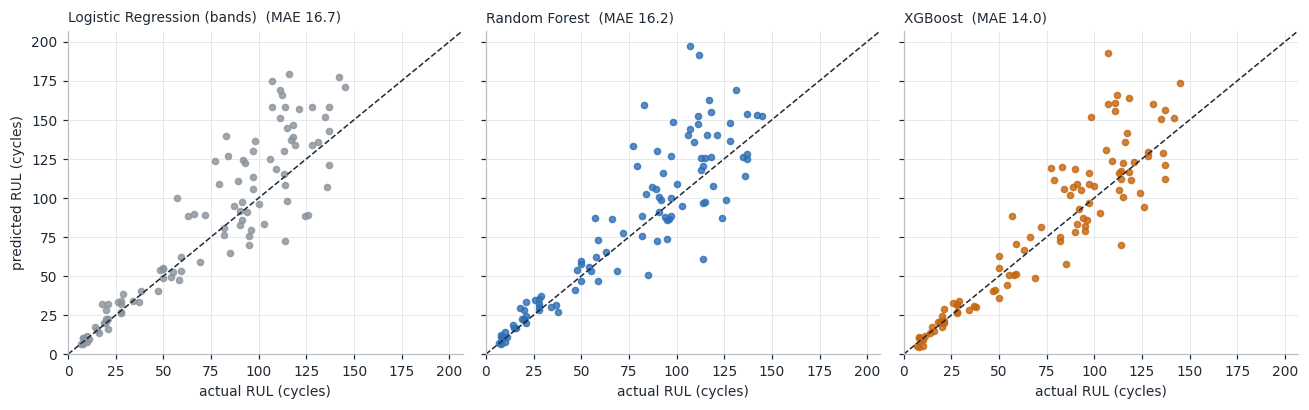

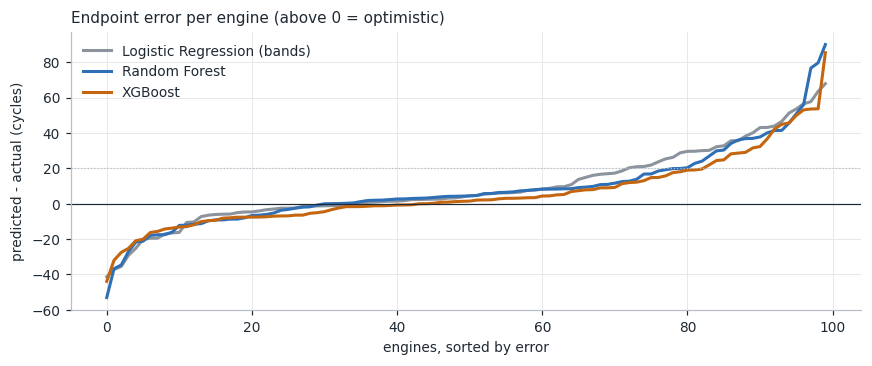

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharex=True, sharey=True)
top = max(y_test_end.max(), *(p.max() for p in pred_end.values())) * 1.05
for ax, (name, p) in zip(axes, pred_end.items()):
    ax.scatter(y_test_end, p, s=16, color=COLORS[name], alpha=0.8)
    ax.plot([0, top], [0, top], ls="--", color=INK, lw=1)
    ax.set_title(f"{name}  (MAE {np.mean(np.abs(p - y_test_end)):.1f})", loc="left", fontsize=9)
    ax.set_xlabel("actual RUL (cycles)")
axes[0].set_ylabel("predicted RUL (cycles)")
ax.set_xlim(0, top); ax.set_ylim(0, top)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.4))
for name, p in pred_end.items():
    ax.plot(np.sort(p - y_test_end), color=COLORS[name], lw=2, label=name)
ax.axhline(0, color=INK, lw=0.8)
ax.axhline(OVER_TOL, color="#B8BEC6", lw=0.8, ls=":")
ax.set_xlabel("engines, sorted by error")
ax.set_ylabel("predicted - actual (cycles)")
ax.set_title("Endpoint error per engine (above 0 = optimistic)", loc="left", fontsize=10)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Per-engine predictions and saved outputs

The key includes the dataset split (`dataset_id`) so test engine 1 is never confused with training engine 1. Outputs go to `artifacts/model/`.

In [9]:
per_engine = pd.DataFrame({
    "dataset_id": "FD001_test", "engine_id": test_end["engine_id"], "observed_cycle": test_end["last_cycle"],
    "actual_rul": y_test_end,
    **{f"{n} predicted": pred_end[n] for n in models},
    **{f"{n} error": pred_end[n] - y_test_end for n in models},
})
display(per_engine.head(10))

worst = per_engine.assign(worst=per_engine[[f"{n} error" for n in models]].abs().max(axis=1)).nlargest(5, "worst")
print("Five engines where the largest model error is biggest:")
display(worst.drop(columns="worst"))

if SAVE_OUTPUTS:
    out_dir = ROOT / "artifacts" / "model"
    out_dir.mkdir(parents=True, exist_ok=True)
    per_engine.to_csv(out_dir / "test_endpoint_predictions_logit_rf_xgb_tuned.csv", index=False)
    endpoint_table.to_csv(out_dir / "test_metrics_endpoint_logit_rf_xgb_tuned.csv")
    traj_table.to_csv(out_dir / "test_metrics_trajectory_logit_rf_xgb_tuned.csv")
    print("\nSaved to artifacts/model/: test_endpoint_predictions_logit_rf_xgb_tuned.csv, "
          "test_metrics_endpoint_logit_rf_xgb_tuned.csv, test_metrics_trajectory_logit_rf_xgb_tuned.csv")

,dataset_id,engine_id,observed_cycle,actual_rul,Logistic Regression (bands) predicted,Random Forest predicted,XGBoost predicted,Logistic Regression (bands) error,Random Forest error,XGBoost error
0,FD001_test,1,31,112.00,165.62,191.66,165.56,53.62,79.66,53.56
1,FD001_test,2,49,98.00,136.21,148.86,151.66,38.21,50.86,53.66
2,FD001_test,3,126,69.00,58.69,52.92,48.96,-10.31,-16.08,-20.04
3,FD001_test,4,106,82.00,76.16,75.36,72.66,-5.84,-6.64,-9.34
4,FD001_test,5,98,91.00,85.98,91.10,83.45,-5.02,0.10,-7.55
5,FD001_test,6,105,93.00,122.64,115.81,105.19,29.64,22.81,12.19
6,FD001_test,7,160,91.00,97.60,100.81,108.60,6.60,9.81,17.60
7,FD001_test,8,166,95.00,75.50,85.85,81.88,-19.50,-9.15,-13.12
8,FD001_test,9,55,111.00,151.08,152.38,160.94,40.08,41.38,49.94
9,FD001_test,10,192,96.00,79.49,86.36,85.88,-16.51,-9.64,-10.12


Five engines where the largest model error is biggest:


,dataset_id,engine_id,observed_cycle,actual_rul,Logistic Regression (bands) predicted,Random Forest predicted,XGBoost predicted,Logistic Regression (bands) error,Random Forest error,XGBoost error
77,FD001_test,78,72,107.00,174.86,197.02,192.39,67.86,90.02,85.39
0,FD001_test,1,31,112.00,165.62,191.66,165.56,53.62,79.66,53.56
14,FD001_test,15,76,83.00,139.49,159.71,119.76,56.49,76.71,36.76
86,FD001_test,87,56,116.00,179.54,140.05,135.62,63.54,24.05,19.62
21,FD001_test,22,39,111.00,168.72,147.08,155.89,57.72,36.08,44.89



Saved to artifacts/model/: test_endpoint_predictions_logit_rf_xgb_tuned.csv, test_metrics_endpoint_logit_rf_xgb_tuned.csv, test_metrics_trajectory_logit_rf_xgb_tuned.csv


## 9. Check the saved models in `model_save/`

`03_model_tuning.ipynb` saved the three tuned models as `.joblib` bundles in `model_save/`. This section loads them and scores the **same 13,096 test rows** (and the 100 endpoints), to see whether the results hold up.

**One difference to expect.** The saved models were trained on the **70 training engines** of the 70:30 split, while sections 3 to 8 above refit the same settings on **all 100 training engines**. The test scores will therefore not match exactly, and the gap tells you what the extra 30 engines are worth. A second check below confirms that the loaded files themselves are faithful, apart from that training-set difference.

In [10]:
import sys
import platform
import warnings
import joblib
import sklearn
import xgboost

sys.path.insert(0, str(ROOT))                       # lets joblib import src.rul_models (needed for the logistic model)
import importlib
import src.rul_models
importlib.reload(src.rul_models)                    # pick up edits to src/rul_models.py without restarting the kernel
from src.rul_models import predict_rul

SAVE_DIR = ROOT / "model_save"
SAVED_FILES = {"Logistic Regression (bands)": "logistic_regression_bands.joblib",
               "Random Forest": "random_forest.joblib", "XGBoost": "xgboost.joblib"}

with warnings.catch_warnings():
    warnings.simplefilter("ignore")                 # version warnings are printed explicitly below instead
    bundles = {name: joblib.load(SAVE_DIR / f) for name, f in SAVED_FILES.items()}

now = {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "joblib": joblib.__version__}
saved_versions = bundles["XGBoost"]["versions"]
print("library versions   saved with  ->  running now")
for k in now:
    flag = "" if saved_versions.get(k) == now[k] else "   <-- differs"
    print(f"  {k:<13} {saved_versions.get(k, '?'):<10} ->  {now[k]}{flag}")
if any(saved_versions.get(k) != now[k] for k in ("scikit-learn", "xgboost")):
    print("Different library versions can change how a pickled model behaves. The faithfulness check in the next cell tests this directly.")

# the saved feature list must match the features built above, in the same order
for name, b in bundles.items():
    assert list(b["features"]) == FEATURES, f"{name}: saved feature list differs from the features built here"
    print(f"{name:<28} {b['feature_set']} features ({len(b['features'])}), target {b['target']}, trained on {len(b['train_engine_ids'])} engines")

saved_all = {name: predict_rul(b, test_f) for name, b in bundles.items()}
saved_end = {name: p[end_mask] for name, p in saved_all.items()}
for name, p in saved_all.items():
    assert len(p) == len(test_f) == 13096 and np.isfinite(p).all(), f"bad predictions from saved {name}"
print(f"\nLoaded all three saved models and predicted {len(test_f):,} test rows ({end_mask.sum()} endpoints).")

saved_endpoint = pd.DataFrame(
    [{**report(y_test_end, saved_end[n], n), "NASA score": nasa_score(saved_end[n] - y_test_end)} for n in models]).set_index("model")
saved_traj = pd.DataFrame(
    [report(y_test_all, saved_all[n], n, engine_ids=test_f["engine_id"].to_numpy()) for n in models]).set_index("model")

print("\nSAVED MODELS (trained on 70 engines), endpoint view, 100 engines:")
display(saved_endpoint)
print("SAVED MODELS (trained on 70 engines), all 13,096 test rows:")
display(saved_traj)

library versions   saved with  ->  running now
  python        3.9.6      ->  3.9.6
  scikit-learn  1.6.1      ->  1.6.1
  xgboost       2.1.4      ->  2.1.4
  joblib        1.5.3      ->  1.5.3
Logistic Regression (bands)  extended features (97), target raw, trained on 70 engines
Random Forest                extended features (97), target sqrt, trained on 70 engines
XGBoost                      extended features (97), target sqrt, trained on 70 engines

Loaded all three saved models and predicted 13,096 test rows (100 endpoints).

SAVED MODELS (trained on 70 engines), endpoint view, 100 engines:


/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/joseph/Desktop/RUL_prediction/TurbofanHPC_RUL_prediction/src/rul_models.py:37: RuntimeWarning: divide by zero encountered in matmul
  return self.clf.predict_proba(self.scaler.transform(X)) @ self.centres
/Users/joseph/Desktop/RUL_prediction/TurbofanHPC_RUL_prediction/src/rul_models.py:37: RuntimeWarning: overflow encountered in matmul
  return self.clf.predict_proba(self.scaler.transform(X)) @ self.centres
/Users/joseph/Desktop/RUL_prediction/TurbofanHPC_RUL_prediction/src/rul_models.py:37:

,n,MAE,RMSE,R2,mean signed error,over by >20 (%),NASA score
model,,,,,,,
Logistic Regression (bands),100,17.70,24.72,0.65,9.38,27.00,"3,717.57"
Random Forest,100,14.36,21.47,0.73,5.32,15.00,"11,167.79"
XGBoost,100,14.57,21.85,0.72,5.75,19.00,"7,372.18"


SAVED MODELS (trained on 70 engines), all 13,096 test rows:


,n,MAE,RMSE,R2,mean signed error,over by >20 (%),engine-avg MAE,engine-avg RMSE
model,,,,,,,,
Logistic Regression (bands),13096,29.12,39.43,0.55,-4.50,25.77,27.92,32.05
Random Forest,13096,30.54,42.20,0.49,-12.21,19.27,28.44,31.79
XGBoost,13096,30.99,42.55,0.48,-11.22,19.93,29.71,33.96


### Saved models (70 engines) against the models refit above (100 engines)

A positive difference means the saved 70-engine model scores higher on that measure. For MAE and RMSE, lower is better, so a positive difference means the saved model is worse.

In [11]:
cmp_cols = ["MAE", "RMSE", "R2", "mean signed error"]
for label, saved_t, full_t in (("ENDPOINT (100 engines)", saved_endpoint, endpoint_table), ("ALL ROWS (13,096)", saved_traj, traj_table)):
    cmp = pd.concat({"saved, 70 engines": saved_t[cmp_cols], "refit, 100 engines": full_t[cmp_cols],
                     "difference": saved_t[cmp_cols] - full_t[cmp_cols]}, axis=1)
    print(label)
    display(cmp)

row_gap = pd.DataFrame({n: np.abs(saved_all[n] - pred_all[n]) for n in models})
print("How far apart the two sets of predictions are, per test row (cycles):")
display(row_gap.describe().loc[["mean", "50%", "max"]].rename(index={"50%": "median"}))

ENDPOINT (100 engines)


saved, 70 engines                              refit, 100 engines                              difference              \
                                          MAE  RMSE   R2 mean signed error                MAE  RMSE   R2 mean signed error        MAE  RMSE    R2   
model                                                                                                                                               
Logistic Regression (bands)             17.70 24.72 0.65              9.38              16.72 23.54 0.68              9.33       0.98  1.18 -0.03   
Random Forest                           14.36 21.47 0.73              5.32              16.22 23.96 0.67              8.18      -1.86 -2.49  0.07   
XGBoost                                 14.57 21.85 0.72              5.75              13.98 20.75 0.75              5.66       0.59  1.10 -0.03   

                                               
                            mean signed error  
model                                          
Logistic Regression (bands)              0.05  
Random Forest                           -2.86  
XGBoost                                  0.09

ALL ROWS (13,096)


saved, 70 engines                              refit, 100 engines                              difference             \
                                          MAE  RMSE   R2 mean signed error                MAE  RMSE   R2 mean signed error        MAE RMSE    R2   
model                                                                                                                                              
Logistic Regression (bands)             29.12 39.43 0.55             -4.50              28.62 38.30 0.58             -1.58       0.50 1.13 -0.03   
Random Forest                           30.54 42.20 0.49            -12.21              30.58 40.88 0.52             -4.53      -0.03 1.32 -0.03   
XGBoost                                 30.99 42.55 0.48            -11.22              29.54 40.24 0.53             -7.06       1.45 2.31 -0.06   

                                               
                            mean signed error  
model                                          
Logistic Regression (bands)             -2.92  
Random Forest                           -7.68  
XGBoost                                 -4.16

How far apart the two sets of predictions are, per test row (cycles):


,Logistic Regression (bands),Random Forest,XGBoost
mean,5.23,9.48,9.69
median,3.86,7.09,7.41
max,83.63,67.33,59.92


### Are the loaded files faithful?

If the library versions differ, a loaded model could in principle behave differently from the one that was saved. To test that, each model is refit here with the same settings on the same 70 training engines stored in its bundle, and its predictions are compared with the loaded file's predictions on all 13,096 test rows. Tiny differences are normal (different library versions, floating-point order). Large differences would mean the loaded copy cannot be trusted in this environment.

In [12]:
def make_fresh(name, b):
    s = dict(b["settings"])
    if name == "Logistic Regression (bands)":
        from src.rul_models import LogitBands
        return LogitBands(**s)
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1, **s)
    return XGBRegressor(random_state=SEED, n_jobs=-1, **s)


from src.rul_models import TARGET_INVERSE
fwd_map = {"raw": lambda y: y, "sqrt": np.sqrt}
faith = []
for name, b in bundles.items():
    rows = train_f[train_f["engine_id"].isin(b["train_engine_ids"])]
    fresh = make_fresh(name, b).fit(rows[b["features"]].to_numpy(float), fwd_map[b["target"]](rows["rul_cycles"].to_numpy(float)))
    refit_pred = np.clip(TARGET_INVERSE[b["target"]](fresh.predict(test_f[b["features"]].to_numpy(float))), 0, None)
    diff = np.abs(refit_pred - saved_all[name])
    faith.append({"model": name, "training rows": len(rows), "mean |diff| (cycles)": diff.mean(),
                  "max |diff| (cycles)": diff.max(), "rows differing by >1 cycle": int((diff > 1).sum()),
                  "MAE refit": float(np.mean(np.abs(refit_pred[end_mask] - y_test_end))),
                  "MAE loaded": float(np.mean(np.abs(saved_end[name] - y_test_end)))})
faith = pd.DataFrame(faith).set_index("model")
display(faith)
verdict = "match" if (faith["max |diff| (cycles)"] < 1).all() else "do NOT all match"
print(f"The loaded models and fresh refits on the same 70 engines {verdict} (largest gap {faith['max |diff| (cycles)'].max():.4f} cycles).")

if SAVE_OUTPUTS:
    saved_endpoint.to_csv(out_dir / "test_metrics_endpoint_saved_models_70_engines.csv")
    saved_traj.to_csv(out_dir / "test_metrics_trajectory_saved_models_70_engines.csv")
    faith.to_csv(out_dir / "saved_models_faithfulness_check.csv")
    print("Saved the saved-model metrics and the faithfulness check to artifacts/model/.")

/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:203: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights.T + intercept  # ndarray, likely C-contiguous
/Users/joseph/Desktop/RUL_prediction/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:336: RuntimeWarning: divide by zero encountered in matmul
  grad[:, :n_features] = grad_pointwise.T @ X + l2_reg_strength * weights
/Users/joseph/Desktop/RUL_prediction/.

,training rows,mean |diff| (cycles),max |diff| (cycles),rows differing by >1 cycle,MAE refit,MAE loaded
model,,,,,,
Logistic Regression (bands),14128,0.00,0.00,0,17.70,17.70
Random Forest,14128,0.00,0.00,0,14.36,14.36
XGBoost,14128,0.00,0.00,0,14.57,14.57


The loaded models and fresh refits on the same 70 engines match (largest gap 0.0000 cycles).
Saved the saved-model metrics and the faithfulness check to artifacts/model/.


## 10. Check against `RUL_FD001.csv`, print the errors and recommend a model

This section rebuilds the comparison **straight from the raw answer file**, without using the notebook's earlier truth columns:

1. Read `RUL_FD001.csv` (the true RUL of each test engine at its last observed cycle) and `test_FD001.csv` (to find each engine's last cycle).
2. Line up each model's prediction at that last cycle with the answer, engine by engine.
3. Print the error for every engine (predicted minus actual, so positive means optimistic), then summary measures.
4. Rank the three models and recommend one.

It is run for both sets of models: the **saved models** in `model_save/` (trained on 70 engines) and the **refit models** from sections 3 to 8 (trained on 100 engines).

In [13]:
# ---- 1. the answers, built only from the raw files ---------------------------------------
rul_file = pd.read_csv(CSV_DIR / "RUL_FD001.csv")                    # engine_id, remaining_cycles
raw_test = pd.read_csv(CSV_DIR / "test_FD001.csv")
last = raw_test.groupby("engine_id")["cycle"].max().rename("last_cycle").reset_index()
answers = rul_file.merge(last, on="engine_id").sort_values("engine_id").reset_index(drop=True)
assert len(answers) == 100 and answers["engine_id"].is_unique
ACTUAL = answers["remaining_cycles"].to_numpy(float)
print(f"{len(answers)} test engines. Answer range: {ACTUAL.min():.0f} to {ACTUAL.max():.0f} cycles, mean {ACTUAL.mean():.1f}.")


def at_endpoints(pred_dict):
    # each model's prediction at the engine's last observed cycle, in the order of the answer file
    return {n: pd.Series(p, index=test_end["engine_id"]).loc[answers["engine_id"]].to_numpy(float) for n, p in pred_dict.items()}


MODEL_SETS = {
    "Saved models (model_save, 70 engines)": at_endpoints(saved_end),
    "Refit models (sections 3-8, 100 engines)": at_endpoints(pred_end),
}

# ---- 2. per-engine errors for the saved models --------------------------------------------
saved_preds = MODEL_SETS["Saved models (model_save, 70 engines)"]
engine_errors = pd.DataFrame({"engine_id": answers["engine_id"], "last_cycle": answers["last_cycle"], "actual_rul": ACTUAL})
for n, p in saved_preds.items():
    engine_errors[f"{n} predicted"] = p
for n, p in saved_preds.items():
    engine_errors[f"{n} error"] = p - ACTUAL

err_cols = [f"{n} error" for n in saved_preds]
print("\nERRORS PER ENGINE, saved models (predicted - actual, cycles). First 15 engines:")
display(engine_errors.head(15))

engine_errors["largest |error|"] = engine_errors[err_cols].abs().max(axis=1)
print("The 10 engines with the largest error from any model:")
display(engine_errors.nlargest(10, "largest |error|").drop(columns="largest |error|"))

if SAVE_OUTPUTS:
    engine_errors.drop(columns="largest |error|").to_csv(out_dir / "check_vs_RUL_FD001_per_engine_errors.csv", index=False)

100 test engines. Answer range: 7 to 145 cycles, mean 75.5.

ERRORS PER ENGINE, saved models (predicted - actual, cycles). First 15 engines:


,engine_id,last_cycle,actual_rul,Logistic Regression (bands) predicted,Random Forest predicted,XGBoost predicted,Logistic Regression (bands) error,Random Forest error,XGBoost error
0,1,31,112.00,174.13,181.78,163.64,62.13,69.78,51.64
1,2,49,98.00,136.49,147.92,158.46,38.49,49.92,60.46
2,3,126,69.00,59.08,53.04,53.27,-9.92,-15.96,-15.73
3,4,106,82.00,79.12,79.28,76.24,-2.88,-2.72,-5.76
4,5,98,91.00,83.42,85.28,84.32,-7.58,-5.72,-6.68
5,6,105,93.00,128.41,109.67,107.54,35.41,16.67,14.54
6,7,160,91.00,94.76,92.39,99.36,3.76,1.39,8.36
7,8,166,95.00,76.43,77.23,81.53,-18.57,-17.77,-13.47
8,9,55,111.00,147.40,145.32,150.20,36.40,34.32,39.20
9,10,192,96.00,76.25,89.21,88.01,-19.75,-6.79,-7.99


The 10 engines with the largest error from any model:


,engine_id,last_cycle,actual_rul,Logistic Regression (bands) predicted,Random Forest predicted,XGBoost predicted,Logistic Regression (bands) error,Random Forest error,XGBoost error
77,78,72,107.00,170.96,198.29,193.47,63.96,91.29,86.47
0,1,31,112.00,174.13,181.78,163.64,62.13,69.78,51.64
86,87,56,116.00,180.05,128.37,131.33,64.05,12.37,15.33
58,59,94,114.00,174.61,119.68,118.66,60.61,5.68,4.66
1,2,49,98.00,136.49,147.92,158.46,38.49,49.92,60.46
14,15,76,83.00,142.86,128.89,107.08,59.86,45.89,24.08
84,85,34,118.00,146.25,161.98,172.80,28.25,43.98,54.80
44,45,152,114.00,67.23,64.70,59.86,-46.77,-49.30,-54.14
21,22,39,111.00,161.14,144.76,147.98,50.14,33.76,36.98
15,16,113,84.00,133.70,96.00,94.76,49.70,12.00,10.76


In [14]:
# ---- 3. summary measures, for both sets of models ------------------------------------------
summary = {}
for label, preds in MODEL_SETS.items():
    summary[label] = pd.DataFrame(
        [{**report(ACTUAL, preds[n], n), "NASA score": nasa_score(preds[n] - ACTUAL)} for n in preds]).set_index("model")
    print(f"\n{label}: {len(ACTUAL)} engines, scored against RUL_FD001.csv")
    display(summary[label])

# the independent numbers must agree with the tables computed earlier in this notebook
assert np.allclose(summary["Saved models (model_save, 70 engines)"][["MAE", "RMSE"]], saved_endpoint[["MAE", "RMSE"]], atol=1e-6)
assert np.allclose(summary["Refit models (sections 3-8, 100 engines)"][["MAE", "RMSE"]], endpoint_table[["MAE", "RMSE"]], atol=1e-6)
print("\nCheck passed: MAE and RMSE here match the tables in sections 5 and 9.")


Saved models (model_save, 70 engines): 100 engines, scored against RUL_FD001.csv


,n,MAE,RMSE,R2,mean signed error,over by >20 (%),NASA score
model,,,,,,,
Logistic Regression (bands),100,17.70,24.72,0.65,9.38,27.00,"3,717.57"
Random Forest,100,14.36,21.47,0.73,5.32,15.00,"11,167.79"
XGBoost,100,14.57,21.85,0.72,5.75,19.00,"7,372.18"



Refit models (sections 3-8, 100 engines): 100 engines, scored against RUL_FD001.csv


,n,MAE,RMSE,R2,mean signed error,over by >20 (%),NASA score
model,,,,,,,
Logistic Regression (bands),100,16.72,23.54,0.68,9.33,28.00,"3,289.65"
Random Forest,100,16.22,23.96,0.67,8.18,20.00,"14,310.24"
XGBoost,100,13.98,20.75,0.75,5.66,17.00,"6,447.69"



Check passed: MAE and RMSE here match the tables in sections 5 and 9.


In [15]:
# ---- 4. rank the three models and recommend one ---------------------------------------------
# five measures; for each, rank 1 = best. R2 is higher-is-better, the rest lower-is-better.
RANK_MEASURES = {"MAE": True, "RMSE": True, "R2": False, f"over by >{OVER_TOL} (%)": True, "NASA score": True}


def rank_models(tbl):
    ranks = pd.DataFrame({m: tbl[m].rank(ascending=asc, method="min") for m, asc in RANK_MEASURES.items()})
    ranks["average rank"] = ranks.mean(axis=1)
    return ranks.sort_values(["average rank"]).join(tbl[["RMSE"]].rename(columns={"RMSE": "_rmse"})).sort_values(["average rank", "_rmse"]).drop(columns="_rmse")


def paired_bootstrap(preds, best, n_boot=5000, seed=SEED):
    # resample engines with replacement; how often does `best` have a lower MAE than each other model?
    rng = np.random.default_rng(seed)
    abs_err = {n: np.abs(p - ACTUAL) for n, p in preds.items()}
    idx = rng.integers(0, len(ACTUAL), size=(n_boot, len(ACTUAL)))
    mae = {n: a[idx].mean(axis=1) for n, a in abs_err.items()}
    return {n: float((mae[best] < mae[n]).mean()) for n in preds if n != best}


winners = {}
for label, tbl in summary.items():
    ranks = rank_models(tbl)
    best = ranks.index[0]
    winners[label] = best
    print(f"\n{label}")
    display(ranks)
    wins = paired_bootstrap(MODEL_SETS[label], best)
    print(f"Best by average rank: {best}.")
    for other, share in wins.items():
        print(f"  In {100 * share:.0f}% of 5,000 resamples of the 100 engines, {best} has a lower MAE than {other}.")

print("\n" + "=" * 78)
print("RECOMMENDATION")
saved_label = "Saved models (model_save, 70 engines)"
rec = winners[saved_label]
t = summary[saved_label].loc[rec]
print(f"Recommended model: {rec}.")
print(f"  On the 100 official test engines it has MAE {t['MAE']:.1f} cycles, RMSE {t['RMSE']:.1f} cycles, R2 {t['R2']:.2f}, "
      f"mean error {t['mean signed error']:+.1f} cycles, and overestimates by more than {OVER_TOL} cycles for {t[f'over by >{OVER_TOL} (%)']:.0f}% of engines.")
if len(set(winners.values())) == 1:
    print("  The refit 100-engine models pick the same winner, so the choice does not depend on how much training data was used.")
else:
    print(f"  Note: the refit 100-engine models pick {winners['Refit models (sections 3-8, 100 engines)']} instead, so the ranking is sensitive to the training set.")
print("Caveats: only 100 test engines, so treat small gaps as noise (see the resampling shares above); every model leans optimistic "
      "(positive mean error), which is the risky direction for maintenance; this is a simulated-data demo, not a decision tool.")


Saved models (model_save, 70 engines)


,MAE,RMSE,R2,over by >20 (%),NASA score,average rank
model,,,,,,
Random Forest,1.00,1.00,1.00,1.00,3.00,1.40
XGBoost,2.00,2.00,2.00,2.00,2.00,2.00
Logistic Regression (bands),3.00,3.00,3.00,3.00,1.00,2.60


Best by average rank: Random Forest.
  In 100% of 5,000 resamples of the 100 engines, Random Forest has a lower MAE than Logistic Regression (bands).
  In 61% of 5,000 resamples of the 100 engines, Random Forest has a lower MAE than XGBoost.

Refit models (sections 3-8, 100 engines)


,MAE,RMSE,R2,over by >20 (%),NASA score,average rank
model,,,,,,
XGBoost,1.00,1.00,1.00,1.00,2.00,1.20
Logistic Regression (bands),3.00,2.00,2.00,3.00,1.00,2.20
Random Forest,2.00,3.00,3.00,2.00,3.00,2.60


Best by average rank: XGBoost.
  In 99% of 5,000 resamples of the 100 engines, XGBoost has a lower MAE than Logistic Regression (bands).
  In 100% of 5,000 resamples of the 100 engines, XGBoost has a lower MAE than Random Forest.

RECOMMENDATION
Recommended model: Random Forest.
  On the 100 official test engines it has MAE 14.4 cycles, RMSE 21.5 cycles, R2 0.73, mean error +5.3 cycles, and overestimates by more than 20 cycles for 15% of engines.
  Note: the refit 100-engine models pick XGBoost instead, so the ranking is sensitive to the training set.
Caveats: only 100 test engines, so treat small gaps as noise (see the resampling shares above); every model leans optimistic (positive mean error), which is the risky direction for maintenance; this is a simulated-data demo, not a decision tool.


## Notes and limits

* **Single test run.** The official test labels were opened once, for this notebook, using settings fixed beforehand in `03_model_tuning.ipynb`. If you tune further, do it on validation engines and not on these scores, or the test result stops being an honest estimate (FR03).
* **Saved models use 70 engines.** Section 9 scores the models in `model_save/`, which were trained on the 70 training engines, so they are not identical to the 100-engine refits in sections 3 to 8.
* **Tuned on 70 engines, refit on 100.** The settings were chosen with cross-validation inside the 70 training engines. Refitting on all 100 uses more data but the settings were not re-tuned for it.
* **Only 100 test engines.** Endpoint metrics rest on 100 predictions, so small differences between models are within noise.
* **Cycle number is an input.** The extended feature set includes the engine's cycle count (age so far). It is known at prediction time, but the model partly learns "older engine, shorter remaining life", which is worth knowing when explaining the result (FRD notes a cycle-only diagnostic for exactly this reason).
* **Point estimates only.** No uncertainty band is shown, and cycles cannot be converted to calendar time.
* **Simulated data, FD001 only.** One operating condition and one fault mode. These results say nothing about real aircraft engines.